Public-contract revision 2026-10-29

V2 replaces finite MEM field identity with the same degree-weighted signed coefficient entropy (mB=100G) and unchanged chi-square/sample<=1.002. An independent ring Fourier/latitude LS recovers source-space coefficients with full-field relative error2.01e-15. Independent zero-start convex coefficient optimization on the measured profiles yields entropy cost12653.19846698 and chi-square/sample1.00006374855, both passing; zero and wrong-sign fields fail. No actual field truth exists. Hidden arrays loaded are theoretical geometry/local profile calibration only, never the reconstructed field. Source algorithm and output bytes unchanged. Historical v1 reference NCC/NRMSE tables remain parity diagnostics; current v2 acceptance uses entropy and all profiles.

# LO Peg: reconstructing the vector magnetic field


<!-- inverse-evidence-audit:20261026:start -->

> **本次维护说明：** 以下导航依据当前观测文件、实际求解代码和保留的输出编写。本次仅完善叙述，不把历史图、缓存结果或未执行代码称作本次新计算；没有独立 GT 时，方法参考不代表真实准确性。

### 观测 → 物理目标：lopeg_zeeman_vector_mapping

**观测 y：** velocity(1, 16, 89)；stokes_i(1, 16, 89)；sigma_i(1, 16, 89)；julian_date(1, 16)；stokes_v(1, 16, 89)；sigma_v(1, 16, 89)。具体单位以本Notebook数据表及README为准。

**恢复目标 x：** 4584面元三分量恒星磁场。

**GT/参考来源：** **没有独立GT：以下仅为原方法参考重建，不能解释为物理真值。**

**由观测恢复目标：** 弱场Zeeman偏振谱为旋转可见面元积分。本地路径为 `preprocessing.reconstruct→solvers.mem_iter`。现有Notebook包含主动调用路径；本次只读审核未重跑，保留的execution_count/图像只说明已有输出，不能声称本轮执行。

**现有实验与图：** 保留图像输出位于cell 7, 9, 11（cell编号按文件内从0计）。章节包括：# LO Peg: reconstructing the vector magnetic field；## 2. Data；## 3. Physics；## 4. Method；## 5. Results；### Forward physics and measured fit；### Spatial reconstruction and observability；### Convergence and actual sensitivity reconstructions；### Interpretation。应联合阅读观测图、完整恢复目标、参考差异与残差/敏感性实验；方法一致性不等于物理精度。

**限制：** 没有独立恒星表面磁场GT；LSD剖面为处理后观测。

<!-- inverse-evidence-audit:20261026:end -->


## 1. Problem

Reconstruct the three-component stellar surface magnetic field from rotationally modulated circular-polarization line profiles with incomplete surface visibility.

Sixteen real normalized LSD mean-line observations of LO Peg from August 2014 are bound to this task. Rotation turns wavelength into a changing spatial encoding. The reconstruction is a surface field, not a scalar line fit. The original author code is run independently and archived; this notebook executes only cleaned local modules. There is no measured true surface map. **Upstream** means our actual unchanged-source run; **fresh** means calculations executed below, not a paper or cached performance report.


## 2. Data

All arrays in `data/raw_data.npz` use a leading batch axis of one. Epoch order follows increasing Julian date; velocity samples remain in their measured order.

| Key | Shape | Dtype | Description |
| --- | --- | --- | --- |
| velocity | (1, 16, 89) | float64 | Measured Doppler velocity before systemic-velocity subtraction, km/s. |
| stokes_i | (1, 16, 89) | float64 | Continuum-normalized intensity I, dimensionless. |
| sigma_i | (1, 16, 89) | float64 | Reported one-sigma uncertainty of normalized I, dimensionless. |
| julian_date | (1, 16) | float64 | Observation Julian date, days. |
| stokes_v | (1, 16, 89) | float64 | Circular polarization V divided by continuum intensity, dimensionless; source sign retained. |
| sigma_v | (1, 16, 89) | float64 | Reported one-sigma uncertainty of normalized V, dimensionless. |

**Acquisition metadata**

| Parameter | Value | Unit | Meaning |
| --- | --- | --- | --- |
| Inclination | 45 | deg | Rotation axis to line of sight. |
| Projected equatorial speed | 67.7 | km/s | Adopted vsini. |
| Equatorial period | 0.4232 | day | P in the phase and shape models. |
| Equator-pole shear | 0.02 | rad/day | dOmega; equator rotates faster. |
| Reference epoch | 2456892.015 | Julian day | Longitude-zero reference. |
| Systemic velocity | -19.8 | km/s | Vr for every observation. |
| Included velocity range | -80 to 80 | km/s | Relative to Vr; inclusive measured sample selection. |
| Stellar mass | 0.66 | solar mass | Roche shape input. |
| Adopted polar radius scale | 0.72 | solar radius | Shape input; independent of velocity scale. |
| Gravitational constant | 6.67408e-11 | m^3 kg^-1 s^-2 | Roche convention. |
| Solar mass | 1.98892e30 | kg | Mass conversion. |
| Solar radius | 6.955e8 | m | Radius conversion. |
| Speed of light | 299792.458 | km/s | Wavelength and Doppler conversion. |
| Mean wavelength | 650 | nm | lambda0 of the LSD line. |
| Intrinsic Gaussian width | 2.41 | km/s | sqrt(2) sigma, not FWHM. |
| Lorentz/Gaussian ratio | 0.89 | 1 | Intrinsic Lorentz HWHM divided by Gaussian width. |
| Effective Lande factor | 1.195 | 1 | Weak-field polarization coefficient. |
| Resolving power | 65000 | 1 | Gaussian instrumental FWHM c/R. |
| Limb coefficient | 0.66 | 1 | Linear continuum limb darkening. |
| Gravity exponent | 0.5 | 1 | Continuum scales as normalized effective gravity to beta. |
| Surface coordinate convention | right-handed longitude, colatitude from north | rad | Viewing longitude decreases as rotation phase increases. |
| Time/polarization convention | supplied Stokes V; B_los toward observer positive | 1 | Preserve the weak-field sign above. |


## 3. Physics

The observations are sixteen normalized least-squares-deconvolved (LSD) mean line profiles of LO Peg from August 2014. Treat these already extracted profiles as measured data; no unprovided raw echelle spectra or polarization calibration files are required. The supplied standard deviations are marginal errors. Use their diagonal weighting as a modeling assumption; the LSD extraction covariance is unavailable.

Let surface cell j have colatitude theta, longitude phi, area A, outward normal n and relative brightness b. At observing epoch o the unit viewing direction is u, projected rotational velocity is v, and mu = n dot u. Only mu > 0 contributes. Define the continuum weight W = A mu (1-eta+eta mu) g^beta on visible cells and zero otherwise, where eta is the linear limb coefficient and g is effective gravity normalized to polar gravity. Differential rotation has angular speed Omega(theta)=2 pi/P - dOmega cos(theta)^2; phase is Omega(theta)(JD-JDref). Each cell uses a Voigt absorption profile L at its Doppler-shifted rest wavelength lambda/(1+v/c). Its Gaussian width includes instrumental broadening in quadrature, while its Lorentz half-width is preserved.


$$
I_o(\lambda)=\frac{\sum_j W_{oj}b_j L_{oj}(\lambda)}{\sum_j W_{oj}b_j},\qquad
V_o(\lambda)=\frac{\sum_j W_{oj}b_j B_{oj}^{\rm los}D_{oj}(\lambda)}{\sum_j W_{oj}b_j},\quad
D=-4.6686\times10^{-12}\lambda_0^2 g_{\rm eff}\frac{dL}{d\lambda}.
$$


Here I and V are continuum-normalized Stokes profiles, c is the speed of light in km/s, wavelengths are in nm, g_eff is the effective Lande factor, and B_los = u dot B is positive toward the observer in G. The coefficient is consequently in the nm/G convention. The measured velocity is converted to rest wavelength by lambda = lambda0[1+(velocity-Vr)/c]. The adopted scalar local absorption strength is calibrated from the measured mean intensity equivalent width using the uniform unit-brightness, zero-field model; it is not an independently supplied target map. Evaluate the discrete equivalent-width integral with right rectangular velocity-bin widths and repeat the last width at the final point.

The unknown is the spatial vector field B, with brightness fixed to b=1; the measured Stokes I channel is used only for line-strength calibration. The I-derived brightness task is not an input to this inversion. Opposite polarities cancel in V, and a single line-of-sight component at each phase cannot uniquely determine every surface vector.


We assume the adopted Roche geometry, fixed local atmosphere and diagonal supplied variances. The angular mesh spacing is a discretization, not a spatial-resolution claim. Invisible or weakly projected regions remain prior dominated. Opposite polarities cancel in circular polarization; brightness and magnetic vector inversions consequently constrain different unknowns.


## 4. Method

Expand radial and tangential components in vector spherical harmonics and maximize a signed-coefficient entropy subject to the weighted spectral misfit. Degree-dependent entropy weights suppress unconstrained fine structure; both poloidal and toroidal terms are needed. A small search subspace built from entropy and likelihood gradients can control curvature and enforce a target chi-square. Maximum entropy selects one regularized spatial solution; it does not remove the acquisition nullspace or establish the physical uniqueness of a recovered feature.


## 5. Results

The preserved code below contains the active reconstruction and comparison path. Its saved outputs are retained from the earlier execution. This documentation edit does not rerun that path; displayed measurements remain evidence of the stored execution rather than a new numerical run.


In [1]:
from pathlib import Path
import os,time,json,hashlib,importlib.util
import numpy as np
import matplotlib.pyplot as plt
from IPython.display import display
ROOT=Path.cwd()
if not (ROOT/'src').exists(): ROOT=ROOT.parent
os.chdir(ROOT)
import sys
sys.path.insert(0,str(ROOT))
from src.preprocessing import load_data,reconstruct,prepare,project_spatial,MODE
from src.visualization import surface_panel,residual_panel
data=load_data(); upstream=dict(np.load('notebooks/reference_outputs/upstream.npz',allow_pickle=False))
export=Path(os.environ.get('IMAGING_PRIVATE_FIGURES','output/review_figures'));export.mkdir(parents=True,exist_ok=True)
manifest=[]
def save_group(fig,name,**arrays):
    fig.tight_layout()
    for extension in ['png','svg','pdf']:
        path=export/(name+'.'+extension);fig.savefig(path,dpi=170,bbox_inches='tight')
        manifest.append(dict(file=path.name,sha256=hashlib.sha256(path.read_bytes()).hexdigest(),bytes=path.stat().st_size))
    path=export/(name+'_source.npz');np.savez_compressed(path,**arrays)
    manifest.append(dict(file=path.name,sha256=hashlib.sha256(path.read_bytes()).hexdigest(),bytes=path.stat().st_size))
    plt.show()
started=time.perf_counter();fresh,state=reconstruct(data);runtime=time.perf_counter()-started
fresh_profile=project_spatial(fresh,state)
observed=data['stokes_i' if MODE=='brightness' else 'stokes_v'];sigma=data['sigma_i' if MODE=='brightness' else 'sigma_v']
residual=(fresh_profile-observed)/sigma
baseline=upstream['reconstruction'];delta=fresh-baseline
component_axis=[fresh] if MODE=='brightness' else fresh
reference_axis=[baseline] if MODE=='brightness' else baseline
metrics=[dict(component=i,ncc=float(np.vdot(a,b)/(np.linalg.norm(a)*np.linalg.norm(b))),nrmse=float(np.sqrt(np.mean((a-b)**2))/np.ptp(b)),maximum_absolute_difference=float(np.max(np.abs(a-b)))) for i,(a,b) in enumerate(zip(component_axis,reference_axis))]
print('Fresh full reconstruction seconds:',runtime,'iterations:',len(state.history))
print('Fresh spatial-map reprojection chi-square/sample:',np.mean(residual**2))
display(metrics)
spec=importlib.util.spec_from_file_location('independent_review_judge',ROOT/'evaluation/judge.py');judge=importlib.util.module_from_spec(spec);spec.loader.exec_module(judge)
np.savez_compressed('output/reconstruction.npz',reconstruction=fresh[None])
report,status=judge.evaluate('output/reconstruction.npz');assert status==0,report
display(report)
np.savez_compressed('notebooks/reference_outputs/fresh.npz',reconstruction=fresh,profile=fresh_profile,history=state.history,runtime_seconds=runtime)


Fresh full reconstruction seconds: 6.688779299998714 iterations: 6
Fresh spatial-map reprojection chi-square/sample: 1.000000283758349


[{'component': 0,
  'ncc': 1.0000000000000002,
  'nrmse': 1.0661232804447691e-13,
  'maximum_absolute_difference': 4.0955683289212175e-10},
 {'component': 1,
  'ncc': 1.0,
  'nrmse': 1.405229445684432e-13,
  'maximum_absolute_difference': 2.6062707547680475e-10},
 {'component': 2,
  'ncc': 1.0000000000000002,
  'nrmse': 1.0337062940179073e-13,
  'maximum_absolute_difference': 4.0526515476813074e-10}]

{'status': 'pass',
 'passed': True,
 'metrics': {'radial_ncc': 1.0000000000000002,
  'radial_nrmse': 1.0661232804447691e-13,
  'colatitudinal_ncc': 1.0,
  'colatitudinal_nrmse': 1.405229445684432e-13,
  'azimuthal_ncc': 1.0000000000000002,
  'azimuthal_nrmse': 1.0337062940179073e-13,
  'observation_chi2_per_sample': 1.000000283758349},
 'thresholds': {'azimuthal_ncc': {'comparison': '>=', 'boundary': 0.999999999},
  'azimuthal_nrmse': {'comparison': '<=', 'boundary': 1e-07},
  'colatitudinal_ncc': {'comparison': '>=', 'boundary': 0.999999999},
  'colatitudinal_nrmse': {'comparison': '<=', 'boundary': 1e-07},
  'observation_chi2_per_sample': {'comparison': '<=', 'boundary': 1.002},
  'radial_ncc': {'comparison': '>=', 'boundary': 0.999999999},
  'radial_nrmse': {'comparison': '<=', 'boundary': 1e-07}},
 'errors': []}

### Forward physics and measured fit

With continuum weights $W=A\mu(1-\eta+\eta\mu)g^\beta$, brightness $b$, local intensity $L$, and line-of-sight field $B_{\mathrm{los}}$,


$$
I=\frac{\sum_j W_jb_jL_j}{\sum_j W_jb_j},\qquad
V=\frac{\sum_j W_jb_jB_{j,\mathrm{los}}D_j}{\sum_j W_jb_j},\qquad
D=-4.6686\times10^{-12}\lambda_0^2g_{\mathrm{eff}}\frac{dL}{d\lambda}.
$$


Wavelength is in nm, field in gauss, and positive line-of-sight field points toward the observer. The local Humlicek Voigt profile includes Gaussian instrument broadening at resolving power 65000. Scalar line strength is estimated from visible intensity equivalent widths. We retain all sixteen epochs and 89 selected samples. Reduced chi-square below means chi-square divided by sample count, not fitted degrees of freedom. Original error estimates do not establish statistical independence of LSD bins.


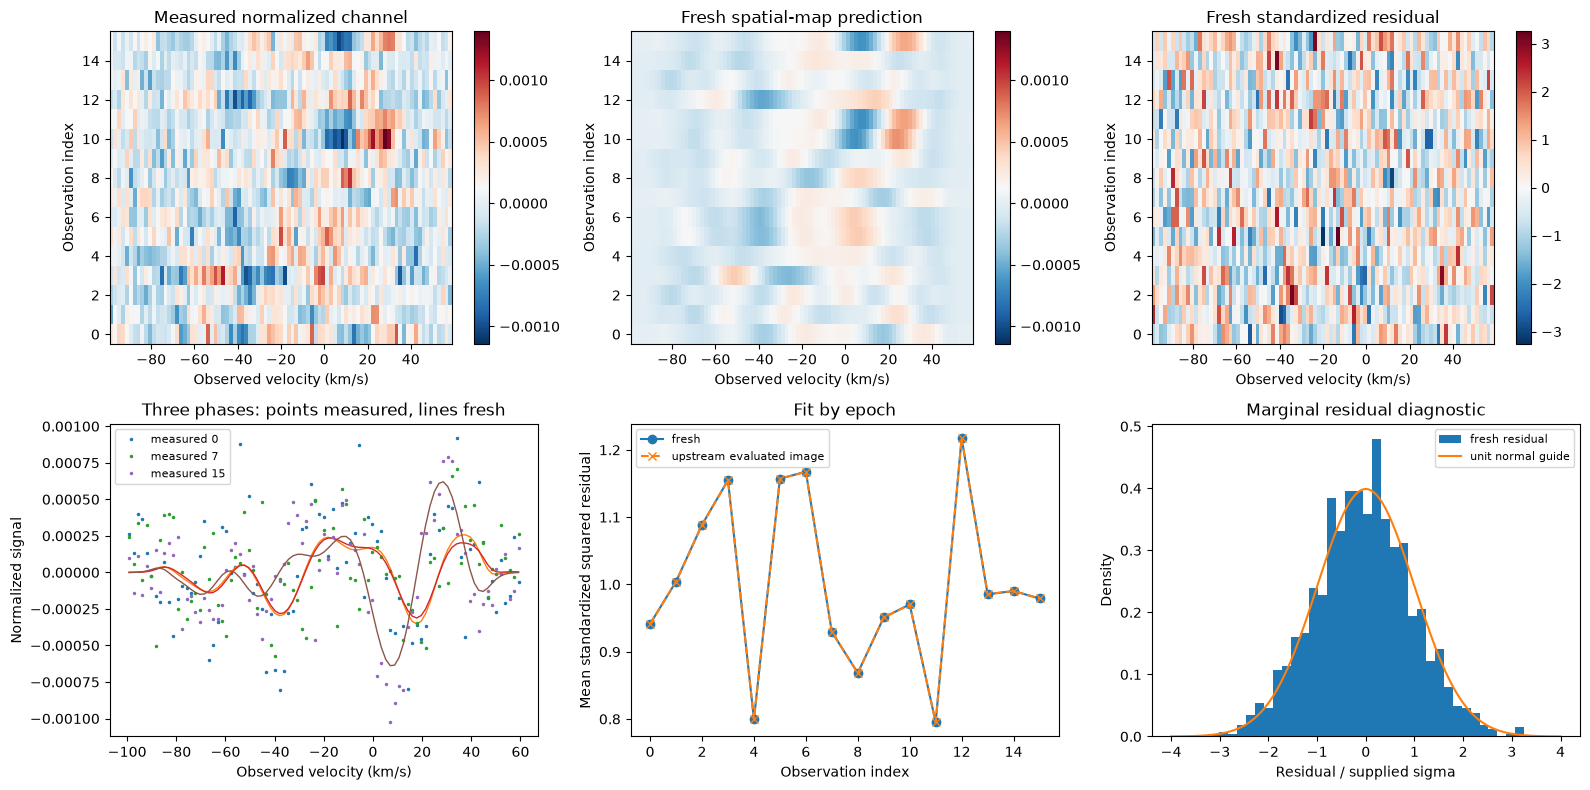

In [2]:
fig,axes=plt.subplots(2,3,figsize=(16,8))
velocity=data['velocity'][0]
for ax,array,title in zip(axes[0],[observed,fresh_profile,residual],['Measured normalized channel','Fresh spatial-map prediction','Fresh standardized residual']):
    im=residual_panel(ax,velocity,array,title)
    if title!='Fresh standardized residual':im.set_clim(min(observed.min(),fresh_profile.min()),max(observed.max(),fresh_profile.max()))
    else:im.set_clim(-np.max(np.abs(residual)),np.max(np.abs(residual)))
    fig.colorbar(im,ax=ax)
for index in [0,7,15]:
    axes[1,0].plot(velocity,observed[index],'.',ms=3,label=f'measured {index}')
    axes[1,0].plot(velocity,fresh_profile[index],'-',lw=1)
axes[1,0].set(xlabel='Observed velocity (km/s)',ylabel='Normalized signal',title='Three phases: points measured, lines fresh');axes[1,0].legend(fontsize=8)
axes[1,1].plot(np.arange(16),np.mean(residual**2,axis=1),'o-',label='fresh')
upres=(upstream['profile']-observed)/sigma
axes[1,1].plot(np.arange(16),np.mean(upres**2,axis=1),'x--',label='upstream evaluated image');axes[1,1].set(xlabel='Observation index',ylabel='Mean standardized squared residual',title='Fit by epoch');axes[1,1].legend(fontsize=8)
axes[1,2].hist(residual.ravel(),bins=35,density=True,label='fresh residual')
z=np.linspace(-4,4,200);axes[1,2].plot(z,np.exp(-z*z/2)/np.sqrt(2*np.pi),label='unit normal guide');axes[1,2].set(xlabel='Residual / supplied sigma',ylabel='Density',title='Marginal residual diagnostic');axes[1,2].legend(fontsize=8)
save_group(fig,'01_observations',velocity=data['velocity'],dates=data['julian_date'],observed=observed,sigma=sigma,fresh_profile=fresh_profile,upstream_profile=upstream['profile'],standardized_residual=residual)


### Spatial reconstruction and observability

The full fitted spatial output is compared with the independently reproduced original result. This is numerical parity, **not** comparison against true starspots or magnetic truth. The observation coverage panel sums normalized projected continuum weights and therefore indicates relative sensitivity, not a reconstructed field. No image alignment is used. The low latitude/hidden hemisphere and polar regions have weaker constraints. Surface area and adopted geometry remain fixed throughout.


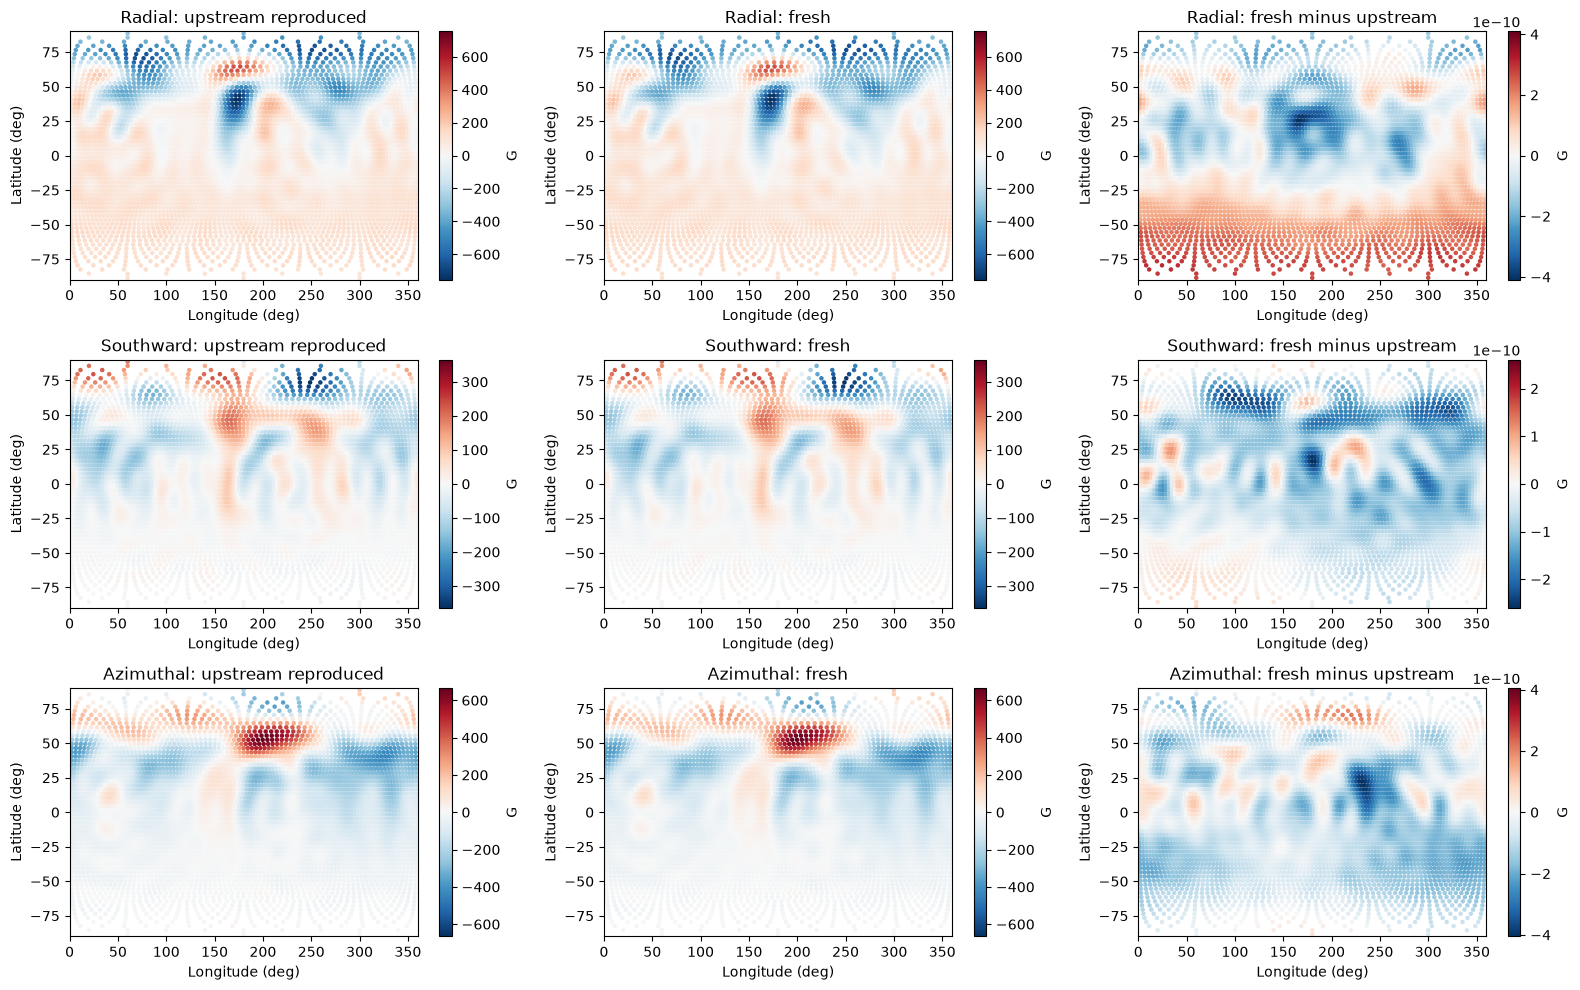

In [3]:
fig,axes=plt.subplots(3,3,figsize=(16,10))
theta=state.grid.clat;phi=state.grid.long
for component,label in enumerate(['Radial','Southward','Azimuthal']):
    limit=np.max(np.abs(np.r_[baseline[component],fresh[component]]))
    for ax,values,title in [(axes[component,0],baseline[component],label+': upstream reproduced'),(axes[component,1],fresh[component],label+': fresh')]:
        im=surface_panel(ax,theta,phi,values,title,'RdBu_r',True);im.set_clim(-limit,limit);fig.colorbar(im,ax=ax,label='G')
    im=surface_panel(axes[component,2],theta,phi,delta[component],label+': fresh minus upstream','RdBu_r',True);fig.colorbar(im,ax=axes[component,2],label='G')
save_group(fig,'02_spatial',colatitude=theta,longitude=phi,radius=state.grid.radius,area=state.grid.area,fresh=fresh,upstream=baseline,difference=delta)


### Convergence and actual sensitivity reconstructions

The weighted misfit is $C=\sum_k[(F_k-d_k)/\sigma_k]^2$, where $d$ is the measured channel, $F$ the predicted channel, and $\sigma$ the supplied marginal standard deviation. The local implementation uses ten search directions from the entropy and misfit gradients, entropy-metric whitening, projected curvature diagonalization and the published two-multiplier step control. Brightness entropy favors the unit photosphere with cell-area weights. Signed magnetic entropy favors zero harmonic coefficients with degree weights. Each iteration records the evaluated image and proposes the next update; stopping requires $C/N\le1.001$ and Test below $10^{-4}$, with $N=1424$ measured samples and a 20-iteration cap.

Targets 0.8, 1.0 and 1.2 below are fresh independent runs. They expose how different fit assumptions change the inferred spatial image. They are sensitivity analyses, not additional measurements or demonstrations of true surface accuracy. The magnetic target 0.8 exhausts the 20-step budget without satisfying both convergence tests; its actual fit and budget limit are reported. The standard target 1.0 converges. The original final brightness proposal aliases its image, while its archived final spectrum belongs to the previous evaluated iterate. We explicitly reproject the returned spatial output for fresh residuals.


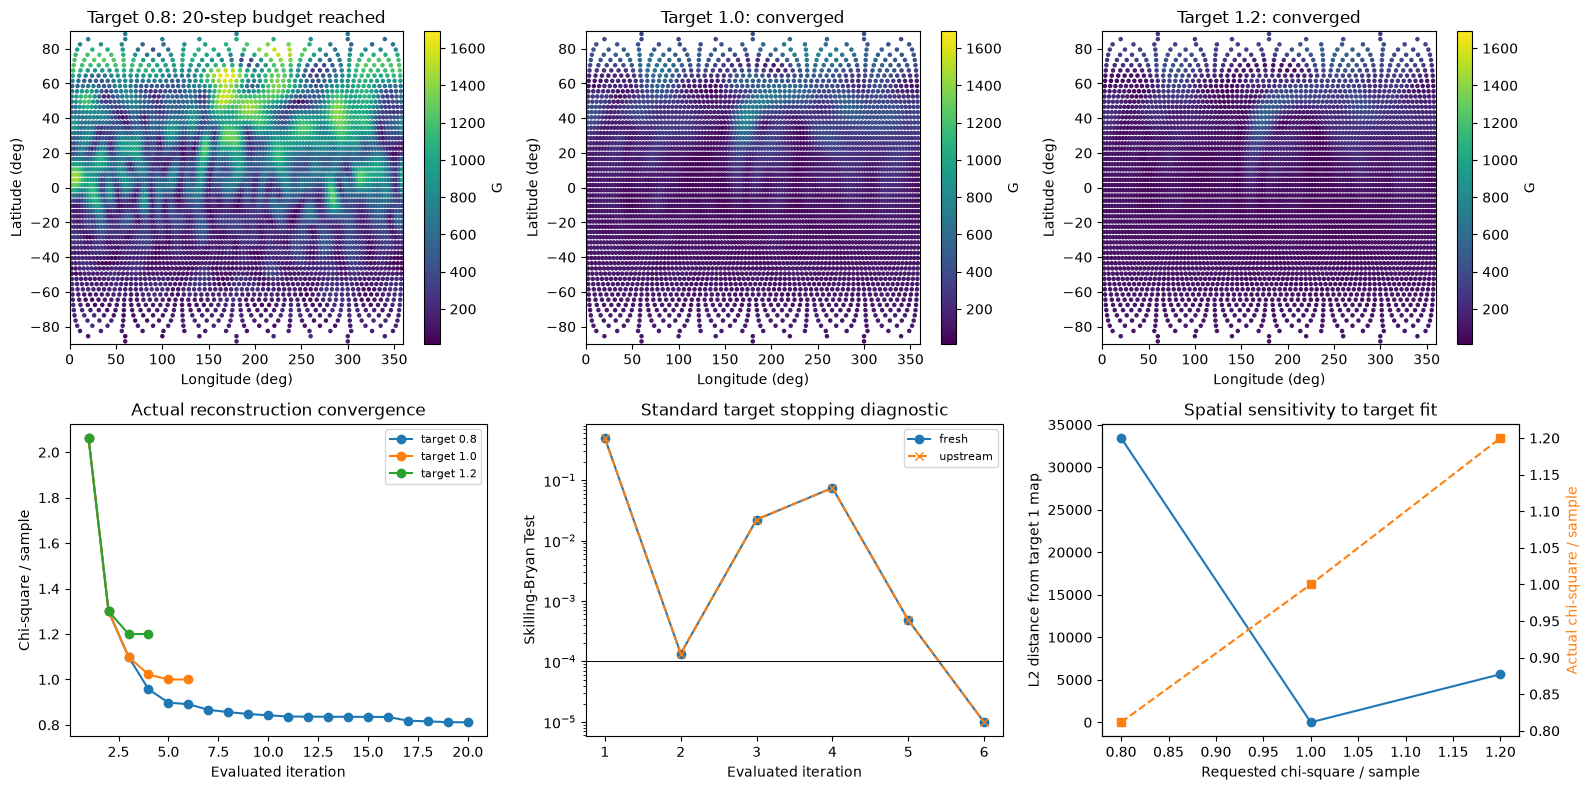

[{'target': 0.8,
  'actual_chi2': 0.8116310558283051,
  'iterations': 20,
  'seconds': 9.505385300002672},
 {'target': 1.0,
  'actual_chi2': 1.000000283758349,
  'iterations': 6,
  'seconds': 7.575302599998395},
 {'target': 1.2,
  'actual_chi2': 1.200001386116124,
  'iterations': 4,
  'seconds': 7.698284600002808}]

1800

In [4]:
targets=np.array([.8,1.,1.2]);sensitivity=[];sensitivity_histories=[];sensitivity_chi=[];sensitivity_seconds=[]
for target in targets:
    start=time.perf_counter();image,current=reconstruct(data,target=float(target));prediction=project_spatial(image,current)
    sensitivity_seconds.append(time.perf_counter()-start);sensitivity.append(image);sensitivity_histories.append(current.history)
    sensitivity_chi.append(float(np.mean(((prediction-observed)/sigma)**2)))
sensitivity=np.array(sensitivity);sensitivity_chi=np.array(sensitivity_chi)
fig,axes=plt.subplots(2,3,figsize=(16,8))
for ax,target,image in zip(axes[0],targets,sensitivity):
    values=image if MODE=='brightness' else np.linalg.norm(image,axis=0)
    index=int(np.flatnonzero(targets==target)[0]);history=sensitivity_histories[index]
    converged=history[-1,1]<=target*observed.size*1.001 and history[-1,2]<1e-4
    im=surface_panel(ax,theta,phi,values,f'Target {target:.1f}: '+('converged' if converged else '20-step budget reached'))
    all_values=sensitivity if MODE=='brightness' else np.linalg.norm(sensitivity,axis=1)
    im.set_clim(np.min(all_values),np.max(all_values))
    fig.colorbar(im,ax=ax,label='Relative brightness' if MODE=='brightness' else 'G')
for history,target in zip(sensitivity_histories,targets):
    axes[1,0].plot(np.arange(1,len(history)+1),history[:,1]/observed.size,'o-',label=f'target {target:.1f}')
axes[1,0].set(xlabel='Evaluated iteration',ylabel='Chi-square / sample',title='Actual reconstruction convergence');axes[1,0].legend(fontsize=8)
axes[1,1].semilogy(np.arange(1,len(state.history)+1),np.maximum(state.history[:,2],1e-18),'o-',label='fresh')
axes[1,1].semilogy(np.arange(1,len(upstream['history'])+1),np.maximum(upstream['history'][:,2],1e-18),'x--',label='upstream');axes[1,1].axhline(1e-4,color='k',lw=.7);axes[1,1].set(xlabel='Evaluated iteration',ylabel='Skilling-Bryan Test',title='Standard target stopping diagnostic');axes[1,1].legend(fontsize=8)
spread=np.sqrt(np.sum((sensitivity-sensitivity[1])**2,axis=tuple(range(1,sensitivity.ndim))))
axes[1,2].plot(targets,spread,'o-',label='Spatial L2 change')
axes[1,2].set(xlabel='Requested chi-square / sample',ylabel='L2 distance from target 1 map',title='Spatial sensitivity to target fit')
second=axes[1,2].twinx();second.plot(targets,sensitivity_chi,'s--',color='tab:orange',label='actual fit');second.set_ylabel('Actual chi-square / sample',color='tab:orange')
save_group(fig,'03_convergence_sensitivity',targets=targets,sensitivity=sensitivity,actual_chi2=sensitivity_chi,spatial_l2_change=spread,standard_history=state.history,upstream_history=upstream['history'],sensitivity_seconds=np.array(sensitivity_seconds),**{f'history_{i}':h for i,h in enumerate(sensitivity_histories)})
display([dict(target=float(t),actual_chi2=float(c),iterations=len(h),seconds=float(s)) for t,c,h,s in zip(targets,sensitivity_chi,sensitivity_histories,sensitivity_seconds)])
(export/'manifest.json').write_text(json.dumps(manifest,indent=2),encoding='utf-8')


### Interpretation

All displayed reconstructions and target sensitivities were computed in this execution. Fresh cleaned results satisfy the independent spatial and observation contracts. The source comparison validates extraction of geometry, line profile physics and entropy updates; it does not establish the astrophysical truth of the vector magnetic field. The adopted atmosphere, inclination, differential rotation and marginal errors are conditional assumptions. Resolution is limited by rotational encoding, intrinsic/instrument line width, viewing coverage and cancellation, with an unconstrained or weakly constrained southern region. The 4584-cell mesh supplies output sampling rather than 4584 independent measurements.

See the self-contained README for units/acquisition and `plan/approach.md` for the implemented equations, proposal convention and stopping rules. Original and fresh measurements remain separately identified. Source revision, licenses, exact observations, backend, commands and numerical differences are recorded in `test/validation.md`.


## 6. Conclusion

The surface mesh is output sampling, not independent spatial resolution. Brightness and vector-field estimates remain conditional on inclination, atmosphere, geometry and marginal errors. The magnetic target-0.8 run reaches its budget, so it is not reported as satisfying both convergence criteria.
